# Подготовка данных БДМО

**База данных муниципальных образований (БДМО)** Росстата содержит сотни показателей по всем муниципальным образованиям России: демографию, экономику, социальную сферу, жилищное строительство и многое другое. Это один из немногих источников статистики, детализированной до уровня муниципалитетов.

Работать с исходной БДМО неудобно, поэтому мы будем использовать данные, подготовленные проектом [«Если быть точным»](https://tochno.st/datasets/bdmo).

В качестве примера возьмём **Калужскую область**: в ней 26 муниципальных образований, их состав в последние годы не менялся, а рядом с областным центром и с Московской областью есть быстро растущие территории.

В этом разделе мы:

- загрузим границы муниципальных образований;
- загрузим статистические показатели, проверим их и приведём к удобному виду;
- объединим статистику с границами по коду ОКТМО и рассчитаем относительный показатель.

## 0. Импорт библиотек

In [1]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings("ignore", message="Numba not installed")  # скрываем техническое предупреждение mapclassify

## 1. Границы муниципальных образований

### 1.1. Загрузка границ

Границы всех муниципальных образований верхнего уровня можно скачать на [геопортале НИУ ВШЭ](https://geoportal.hse.ru/portal/apps/sites/#/geodata/datasets/12e78b9c3bf04feea944f9d53eb3d079/about). Файл содержит границы муниципальных образований Центрального федерального округа. Выберем из них Калужскую область и перепроецируем в UTM, чтобы область на карте не была растянута по горизонтали (см. модуль II):

In [2]:
muni = gpd.read_file("../data/muni2.geojson")

muni = muni[muni["region"] == "Калужская область"]
muni = muni.to_crs(muni.estimate_utm_crs())

print("Муниципальных образований:", len(muni))
muni.head()

Муниципальных образований: 26


,db_j4c1v_h,oktmo,oktmo_num,region,type,name,admcen,note,fo,pop,rur,urb,st_area_sh,st_length_,geometry
162,722,29646000,29646000,Калужская область,муниципальный район,Хвастовичский муниципальный район,с Хвастовичи,None,Центральный,10570,10570,0,4.245920e+09,534846.484731,"MULTIPOLYGON (((666248.92 5922308.947, 666256...."
163,723,29650000,29650000,Калужская область,муниципальный район,Юхновский муниципальный район,г Юхнов,None,Центральный,10279,4553,5726,4.023702e+09,485905.461334,"MULTIPOLYGON (((629664.944 6088366.898, 630170..."
181,725,29715000,29715000,Калужская область,городской округ,город Обнинск,г Обнинск,None,Центральный,116179,0,116179,1.340438e+08,89690.920522,"MULTIPOLYGON (((730439.976 6116264.728, 730472..."
197,700,29602000,29602000,Калужская область,муниципальный район,Бабынинский муниципальный район,п Бабынино,None,Центральный,18313,7910,10403,2.510308e+09,353376.354733,"MULTIPOLYGON (((672785.072 6050205.663, 672842..."
198,701,29604000,29604000,Калужская область,муниципальный район,Барятинский муниципальный район,с Барятино,None,Центральный,5984,5984,0,3.255991e+09,417943.208488,"MULTIPOLYGON (((591659.931 6041605.343, 591832..."


Главное поле для нас — `oktmo`, код муниципального образования по **ОКТМО** (Общероссийскому классификатору территорий муниципальных образований). Именно по нему мы будем присоединять статистику.

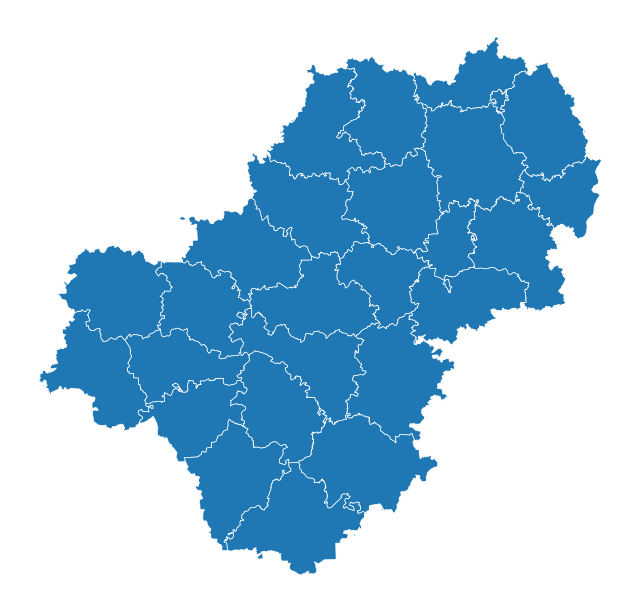

In [3]:
ax = muni.plot(edgecolor="white", linewidth=0.5, figsize=(8, 8))
ax.axis("off")
plt.show()

### 1.2. Проблема изменения границ

Границы муниципальных образований не постоянны. Муниципалитеты объединяют, преобразуют (например, муниципальные районы — в муниципальные округа) и упраздняют. При этом у них часто меняется и код ОКТМО.

Это создаёт две проблемы:

- статистика за прошлые годы может относиться к муниципалитетам, которых уже нет в актуальных границах, и не присоединится к ним. Например, в Московской и Тверской областях после преобразований у многих муниципалитетов нет данных за 2016 год в актуальных границах;
- если муниципалитет сохранил код, но к нему присоединили соседей, его показатели резко «вырастут». Так, Переславль-Залесский в 2018 году объединили с Переславским районом, и по данным его население за 2016–2020 годы «выросло» на 43 %.

Поэтому при выборе лет для сравнения проверяйте, менялись ли за этот период границы муниципалитетов в вашем регионе. В Калужской области за рассматриваемый период состав муниципалитетов не менялся.

## 2. Статистические данные

Данные БДМО от проекта «Если быть точным»:

- полный набор данных и документация — [здесь](https://tochno.st/datasets/bdmo);
- данные по отдельным показателям — [здесь](https://docs.google.com/spreadsheets/d/1Z66eXdgzyBg2NPV4cRzrTtv6BSZFVaAi/edit?pli=1&gid=1495188554#gid=1495188554).

### 2.1. Численность населения

Прочитаем данные о численности населения и оставим только Калужскую область.

> Код ОКТМО может начинаться с нуля (например, у муниципалитетов Алтайского края). Если прочитать его как число, ведущий ноль пропадёт, и данные не присоединятся к границам. Поэтому явно указываем, что `oktmo` — строка.

In [4]:
population = pd.read_csv("../data/bdmo_pop_sample.csv", dtype={"oktmo": str})
population = population[population["region"] == "Калужская область"]

population.head()

,id_rosstat,indicator,vozr,grup_2,migr,mest,nazsostv,region,mun_level,munr,municipality,oktmo,mun_type,year,value,unit,period
5343,8112027,Оценка численности населения на 1 января текущ...,NaN,NaN,NaN,Все население,NaN,Калужская область,1,Бабынинский муниципальный район,Бабынинский муниципальный район,29602000,10,2009,22699.0,чел,"На 1 января (с 2018 г.) года, следующего за от..."
5344,8112027,Оценка численности населения на 1 января текущ...,NaN,NaN,NaN,Все население,NaN,Калужская область,1,Бабынинский муниципальный район,Бабынинский муниципальный район,29602000,10,2010,21042.0,чел,"На 1 января (с 2018 г.) года, следующего за от..."
5345,8112027,Оценка численности населения на 1 января текущ...,NaN,NaN,NaN,Все население,NaN,Калужская область,1,Бабынинский муниципальный район,Бабынинский муниципальный район,29602000,10,2011,20997.0,чел,"На 1 января (с 2018 г.) года, следующего за от..."
5346,8112027,Оценка численности населения на 1 января текущ...,NaN,NaN,NaN,Все население,NaN,Калужская область,1,Бабынинский муниципальный район,Бабынинский муниципальный район,29602000,10,2012,20377.0,чел,"На 1 января (с 2018 г.) года, следующего за от..."
5347,8112027,Оценка численности населения на 1 января текущ...,NaN,NaN,NaN,Все население,NaN,Калужская область,1,Бабынинский муниципальный район,Бабынинский муниципальный район,29602000,10,2013,20009.0,чел,"На 1 января (с 2018 г.) года, следующего за от..."


Данные хранятся в **длинном формате**: каждая строка — значение одного показателя для одного муниципалитета за один год. Основные поля:

| Поле                     | Содержание                                         |
| ------------------------ | -------------------------------------------------- |
| `oktmo`                  | код муниципального образования по ОКТМО            |
| `municipality`, `region` | название муниципалитета и региона                  |
| `indicator`, `unit`      | название показателя и единица измерения            |
| `year`                   | год                                                |
| `value`                  | значение показателя                                |
| `mest`                   | тип местности (все население, городское, сельское) |

Посмотрим, какие значения есть в поле `mest`:

In [5]:
population["mest"].value_counts()

mest
Все население          338
Сельское население     325
Городское население    249
Name: count, dtype: int64

Оставим только численность всего населения (без разделения на городское и сельское):

In [6]:
population = population[population["mest"] == "Все население"]

### 2.2. Проверка повторов

Для каждого муниципалитета и года должна быть ровно одна строка. Проверим, нет ли повторов:

In [7]:
population.duplicated(subset=["oktmo", "year"]).sum()

np.int64(0)

Повторов нет. Эта проверка важна: метод `pivot_table()`, которым мы дальше преобразуем таблицу, при повторах **молча усредняет** значения, и ошибка останется незамеченной. В БДМО повторы встречаются: например, в Тамбовской области они есть у 23 муниципалитетов.

### 2.3. Преобразование в широкий формат

Для картографирования удобнее **широкий формат**: одна строка — один муниципалитет, а значения за разные годы — в отдельных столбцах. Преобразуем таблицу с помощью `pivot_table()` и добавим к названиям столбцов префикс, чтобы не перепутать показатели:

In [8]:
population_wide = (
    population
    .pivot_table(index="oktmo", columns="year", values="value")
    .add_prefix("pop_")
    .reset_index()
)

population_wide.head()

year,oktmo,pop_2009,pop_2010,pop_2011,pop_2012,pop_2013,pop_2014,pop_2015,pop_2016,pop_2017,pop_2018,pop_2019,pop_2020,pop_2021
0,29602000,22699.0,21042.0,20997.0,20377.0,20009.0,19551.0,19044.0,18708.0,18707.0,18349.0,18306.0,18293.0,18313.0
1,29604000,5307.0,6351.0,6346.0,6249.0,6179.0,6096.0,6041.0,6055.0,6101.0,6032.0,5946.0,6016.0,5984.0
2,29606000,55790.0,61369.0,61297.0,61302.0,61087.0,60825.0,60516.0,60879.0,61620.0,61761.0,62711.0,62376.0,63220.0
3,29608000,59846.0,60747.0,60226.0,60188.0,56141.0,55148.0,54299.0,53559.0,53266.0,52951.0,52799.0,52663.0,52464.0
4,29610000,15077.0,15447.0,15186.0,14984.0,14757.0,14680.0,14540.0,14265.0,14163.0,14083.0,13881.0,13823.0,13684.0


### 2.4. Проверка полноты данных

Не для всех муниципалитетов есть данные за все годы. Посчитаем число пропусков по годам:

In [9]:
population_wide.isna().sum()

year
oktmo       0
pop_2009    0
pop_2010    0
pop_2011    0
pop_2012    0
pop_2013    0
pop_2014    0
pop_2015    0
pop_2016    0
pop_2017    0
pop_2018    0
pop_2019    0
pop_2020    0
pop_2021    0
dtype: int64

В Калужской области пропусков нет: данные о численности есть за 2009–2021 годы для всех 26 муниципалитетов. В других регионах так бывает не всегда, например в Тверской области за 2016 год нет данных для 15 муниципалитетов из 42.

### 2.5. Число родившихся

Аналогично прочитаем данные о числе родившихся, проверим повторы и преобразуем таблицу:

In [10]:
birth = pd.read_csv("../data/bdmo_birth_sample.csv", dtype={"oktmo": str})
birth = birth[birth["region"] == "Калужская область"]

print("Повторов:", birth.duplicated(subset=["oktmo", "year"]).sum())

birth_wide = (
    birth
    .pivot_table(index="oktmo", columns="year", values="value")
    .add_prefix("birth_")
    .reset_index()
)

birth_wide.isna().sum()

Повторов: 0


year
oktmo         0
birth_2008    0
birth_2009    0
birth_2010    0
birth_2011    0
birth_2012    0
birth_2013    0
birth_2014    0
birth_2015    0
birth_2016    0
birth_2017    0
birth_2018    0
birth_2019    0
birth_2020    0
dtype: int64

## 3. Объединение данных по ОКТМО

### 3.1. Табличное объединение

Присоединим обе таблицы к границам по полю `oktmo`. Используем `how="left"`, чтобы сохранить все муниципалитеты, даже если для некоторых из них нет данных.

In [11]:
muni["oktmo"] = muni["oktmo"].astype(str)

muni_stat = (
    muni
    .merge(population_wide, on="oktmo", how="left")
    .merge(birth_wide, on="oktmo", how="left")
)

muni_stat.head()

,db_j4c1v_h,oktmo,oktmo_num,region,type,name,admcen,note,fo,pop,...,birth_2011,birth_2012,birth_2013,birth_2014,birth_2015,birth_2016,birth_2017,birth_2018,birth_2019,birth_2020
0,722,29646000,29646000,Калужская область,муниципальный район,Хвастовичский муниципальный район,с Хвастовичи,None,Центральный,10570,...,135.0,146.0,137.0,153.0,103.0,141.0,106.0,101.0,92.0,85.0
1,723,29650000,29650000,Калужская область,муниципальный район,Юхновский муниципальный район,г Юхнов,None,Центральный,10279,...,147.0,142.0,143.0,118.0,103.0,113.0,105.0,103.0,88.0,69.0
2,725,29715000,29715000,Калужская область,городской округ,город Обнинск,г Обнинск,None,Центральный,116179,...,1129.0,1302.0,1335.0,1377.0,1624.0,1526.0,1344.0,1259.0,1087.0,1067.0
3,700,29602000,29602000,Калужская область,муниципальный район,Бабынинский муниципальный район,п Бабынино,None,Центральный,18313,...,282.0,312.0,260.0,267.0,247.0,237.0,190.0,179.0,177.0,168.0
4,701,29604000,29604000,Калужская область,муниципальный район,Барятинский муниципальный район,с Барятино,None,Центральный,5984,...,66.0,58.0,61.0,47.0,47.0,48.0,35.0,38.0,26.0,40.0


### 3.2. Проверка объединения

Проверим, для скольких муниципалитетов не нашлось данных:

In [12]:
print("Муниципалитетов:", len(muni_stat))
print("Без данных о населении:", muni_stat.filter(like="pop_").isna().all(axis=1).sum())
print("Без данных о рождаемости:", muni_stat.filter(like="birth_").isna().all(axis=1).sum())

Муниципалитетов: 26
Без данных о населении: 0
Без данных о рождаемости: 0


Данные нашлись для всех муниципалитетов. Если таких муниципалитетов много, проверьте, совпадают ли форматы кодов ОКТМО в двух таблицах и не менялись ли границы муниципалитетов (см. раздел 1.2). Данных может не быть и по другой причине: например, статистика по закрытым административно-территориальным образованиям (ЗАТО) не публикуется.

## 4. Расчёт относительного показателя

Абсолютное число родившихся зависит прежде всего от численности населения: в крупном муниципалитете детей рождается больше просто потому, что там больше жителей. Как мы обсуждали в разделе [Картограммы и методы классификации](mapping_1.ipynb), картограммы строят по **относительным показателям**.

Рассчитаем **общий коэффициент рождаемости** — число родившихся на 1000 жителей (‰):

In [13]:
muni_stat["birth_rate_2016"] = muni_stat["birth_2016"] / muni_stat["pop_2016"] * 1000
muni_stat["birth_rate_2020"] = muni_stat["birth_2020"] / muni_stat["pop_2020"] * 1000

muni_stat[["birth_rate_2016", "birth_rate_2020"]].describe()

,birth_rate_2016,birth_rate_2020
count,26.000000,26.000000
mean,10.742450,7.670247
std,2.097107,1.565519
min,7.150368,4.268529
25%,9.224867,6.647385
50%,10.440843,7.658053
75%,11.722330,8.509810
max,16.587017,10.743044


Построим картограмму коэффициента рождаемости за 2020 год. Муниципалитеты без данных (если они есть) покажем серым цветом с помощью параметра `missing_kwds`:

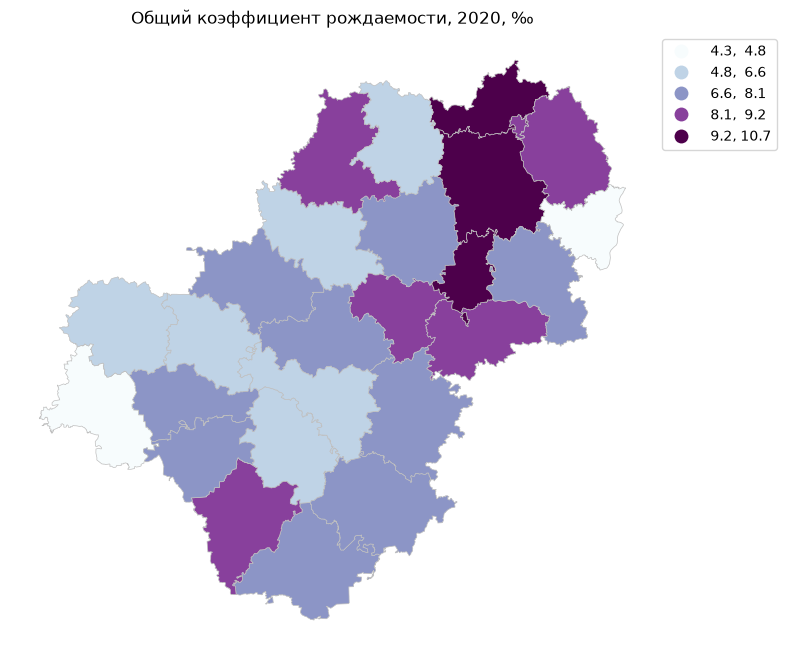

In [14]:
ax = muni_stat.plot(
    column="birth_rate_2020",
    cmap="BuPu",
    scheme="FisherJenks",
    k=5,
    linewidth=0.5,
    edgecolor="0.75",
    legend=True,
    legend_kwds={"loc": "upper left", "bbox_to_anchor": (1, 1), "fmt": "{:.1f}"},
    missing_kwds={"color": "lightgrey", "label": "Нет данных"},
    figsize=(9, 8)
)

ax.set_title("Общий коэффициент рождаемости, 2020, ‰")
ax.axis("off")

plt.show()

## 5. Сохранение результата

Подготовленные данные понадобятся в следующем разделе. Сохраним их в файл, чтобы не повторять все шаги заново:

In [15]:
muni_stat.to_file("../data/muni_stat.gpkg")

## Итог

В этом разделе мы подготовили данные БДМО для картографирования:

1. Загрузили границы муниципальных образований Калужской области и обсудили проблему изменения границ.
2. Загрузили статистику, сохранив коды ОКТМО как строки, проверили повторы и преобразовали таблицы из длинного формата в широкий.
3. Проверили полноту данных за разные годы.
4. Объединили статистику с границами по коду ОКТМО и проверили результат объединения.
5. Рассчитали относительный показатель, построили картограмму и сохранили результат.

В следующем разделе мы сравним карты за разные годы и проверим связь между показателями.